# Nonlinear cold+baryon power: CAMB and CLASS directly

Requires **CAMB, classy, NumPy and Matplotlib** installed in your notebook environment.
No CosmicFishPie, configuration files, or saved data are used.

Compare three curves: **CAMB subtraction**, **CLASS subtraction**, and **CLASS native
nonlinear cb**. Both solvers use HMcode 2020 and three equal-mass neutrinos.
Units: $k$ in Mpc$^{-1}$, $P$ in Mpc$^3$, $M_\nu$ in eV.

The reconstruction assumes linear neutrino and cb–neutrino cross spectra:
$$P_{cb}^{\rm rec}=\frac{P_m^{\rm NL}-2f_{cb}f_\nu P_{cb\nu}^{\rm L}
-f_\nu^2P_{\nu\nu}^{\rm L}}{f_{cb}^2}.$$
Here the fractions are evaluated at $z=0$. This is an approximation, not an
identity for fully nonlinear component spectra. CAMB is a comparison reference,
not a declaration of which prescription is physically more accurate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import camb
import classy
from classy import Class

print("CAMB:", camb.__version__, "CLASS:", getattr(classy, "__version__", "unknown"))

CAMB: 2.0.4 CLASS: v3.4.1


## Cosmology and finite difference

Keep **$A_s$, $n_s$, $h$, $\omega_b$ and $\omega_c$ fixed** when changing
$M_\nu$. Thus total $\Omega_m$ and $\sigma_8$ vary. This is not the
fixed-$\sigma_8$, fixed-total-$\Omega_m$ derivative used in some forecasting
parameterizations. Standard solver thermal-neutrino conventions are retained;
their density conversion can differ slightly.

The central difference uses one step; reduce `dm` to check convergence.
The notebook performs six solver runs, which can take a few minutes.

In [7]:
h = 0.6737
omega_b, omega_c = 0.02237, 0.12
As, ns, pivot = 2.1e-9, 0.96605, 0.05
Mnu, dm, Neff = 0.06, 0.006, 3.044
z = np.array([0.5, 1.0, 2.0])
k = np.geomspace(1e-3, 10.0, 120)
masses = np.array([Mnu - dm, Mnu, Mnu + dm])

## CAMB: reconstruct cb from total nonlinear power

The linear cross spectrum uses `delta_nonu` (cold matter + baryons) and
`delta_nu` (massive neutrinos).

In [3]:
def camb_subtraction(mass):
    pars = camb.CAMBparams()
    pars.set_cosmology(H0=100*h, ombh2=omega_b, omch2=omega_c,
                       mnu=mass, nnu=Neff, num_massive_neutrinos=3,
                       neutrino_hierarchy="degenerate", TCMB=2.7255,
                       YHe=0.2454, tau=0.058)
    pars.InitPower.set_params(As=As, ns=ns, pivot_scalar=pivot)
    pars.set_matter_power(redshifts=[0.0, *z], kmax=20.0)
    pars.NonLinear = camb.model.NonLinear_both
    pars.NonLinearModel.set_params(halofit_version="mead2020")
    results = camb.get_results(pars)
    fnu = results.get_Omega("nu") / (
        results.get_Omega("baryon") + results.get_Omega("cdm")
        + results.get_Omega("nu"))
    fcb = 1 - fnu

    def power(a, b, nonlinear=False):
        interp = results.get_matter_power_interpolator(
            var1=a, var2=b, nonlinear=nonlinear,
            hubble_units=False, k_hunit=False)
        return interp.P(z, k)

    return (power("delta_tot", "delta_tot", True)
            - 2*fcb*fnu*power("delta_nonu", "delta_nu")
            - fnu**2*power("delta_nu", "delta_nu")) / fcb**2

## CLASS: native cb and the same subtraction

Linear transfer functions give $P_{ab}^{\rm L}(k,z)=
(2\pi^2/k^3)A_s(k/k_*)^{n_s-1}T_aT_b$.
The cb transfer is the density-weighted baryon/CDM transfer. With one massive
species representing three degenerate masses, `d_ncdm[0]` is the neutrino transfer.
`pk_cb` directly returns CLASS's native nonlinear cb spectrum when nonlinear
corrections are enabled.

In [ ]:
def class_spectra(mass):
    solver = Class()
    solver.set({
        "h": h, "omega_b": omega_b, "omega_cdm": omega_c,
        "A_s": As, "n_s": ns, "k_pivot": pivot,
        "N_ncdm": 1, "deg_ncdm": 3, "m_ncdm": mass/3,
        "N_ur": 0.0, "T_ncdm": (4/11)**(1/3)*(Neff/3)**0.25,
        "T_cmb": 2.7255, "YHe": 0.2454, "tau_reio": 0.058,
        "output": "mPk,mTk", "non linear": "hmcode2020",
        "P_k_max_1/Mpc": 20.0, "z_max_pk": 3.0,
    })
    try:
        solver.compute()
        fb = solver.Omega_b() / solver.Omega_m()
        fc = solver.Omega0_cdm() / solver.Omega_m()
        fcb, fnu = fb + fc, 1 - fb - fc
        primordial = 2*np.pi**2/k**3 * As*(k/pivot)**(ns - 1)
        reconstructed, native = [], []
        for zz in z:
            transfer = solver.get_transfer(float(zz))
            kt = transfer["k (h/Mpc)"] * h
            assert kt[0] <= k[0] and kt[-1] >= k[-1]
            # Signed transfers: interpolate values, not their logarithms.
            def T(name):
                return np.interp(np.log(k), np.log(kt), transfer[name])
            tcb = (fb*T("d_b") + fc*T("d_cdm")) / fcb
            tnu = T("d_ncdm[0]")
            cross, nunu = primordial*tcb*tnu, primordial*tnu**2
            total = np.array([solver.pk(float(kk), float(zz)) for kk in k])
            reconstructed.append((total - 2*fcb*fnu*cross - fnu**2*nunu)/fcb**2)
            native.append([solver.pk_cb(float(kk), float(zz)) for kk in k])
        return np.array(reconstructed), np.array(native)
    finally:
        solver.struct_cleanup()
        solver.empty()

In [16]:
mass = masses[0]
print(f"mass = {mass}")
solver = Class()
solver.set({
    "h": h, "omega_b": omega_b, "omega_cdm": omega_c,
    "A_s": As, "n_s": ns, "k_pivot": pivot,
    "N_ncdm": 1, "deg_ncdm": 3, "m_ncdm": mass/3,
    "N_ur": 0.0, "T_ncdm": (4/11)**(1/3)*(Neff/3)**0.25,
    "T_cmb": 2.7255, "YHe": 0.2454, "tau_reio": 0.058,
    "output": "mPk,mTk", "non linear": "hmcode2020",
    "P_k_max_1/Mpc": 20.0, "z_max_pk": 3.0,
})
try:
    solver.compute()
    fb = solver.Omega_b() / solver.Omega_m()
    fc = solver.Omega0_cdm() / solver.Omega_m()
    fcb, fnu = fb + fc, 1 - fb - fc
    primordial = 2*np.pi**2/k**3 * As*(k/pivot)**(ns - 1)
finally:
    print("done")
solver.pk_cb?

mass = 0.054
done


Signature: solver.pk_cb(k, z)
Docstring:
Return the CDM+baryon power spectrum P_cb(k,z)

Return the CDM+baryon power spectrum P_cb(k,z) (in Mpc**3) for a given k (in
1/Mpc) and z. The function returns the linear power spectrum
if the user sets 'non_linear' to 'no', and the non-linear
power spectrum otherwise.
This function requires that the 'ouput' field contains at least 'mPk'.

Parameters
----------
k : float
    Wavenumber
z : float
    Redshift

Returns
-------
pk_cb : float
    CDM+baryon power spectrum
Type:      method

In [6]:
spectra = {name: [] for name in
           ("CAMB subtraction", "CLASS subtraction", "CLASS native cb")}
for mass in masses:
    print(f"Mnu = {mass:.3f} eV")
    spectra["CAMB subtraction"].append(camb_subtraction(mass))
    reconstructed, native = class_spectra(mass)
    spectra["CLASS subtraction"].append(reconstructed)
    spectra["CLASS native cb"].append(native)
spectra = {name: np.array(values) for name, values in spectra.items()}
assert all(np.all(np.isfinite(p)) and np.all(p > 0) for p in spectra.values())

Mnu = 0.054 eV
Note: redshifts have been re-sorted (earliest first)
Mnu = 0.060 eV
Note: redshifts have been re-sorted (earliest first)
Mnu = 0.066 eV
Note: redshifts have been re-sorted (earliest first)


## Fiducial spectra and residuals

Residuals are relative to the CAMB subtraction at the same cosmology.

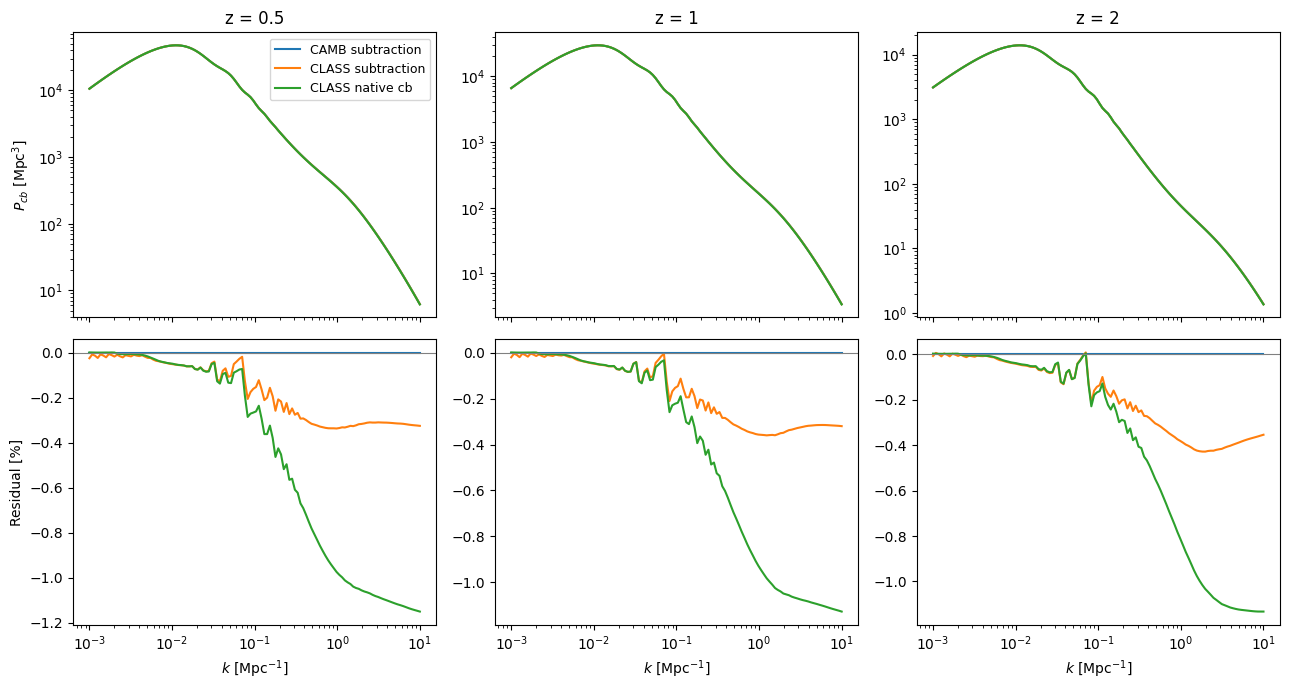

In [7]:
fig, axes = plt.subplots(2, len(z), figsize=(13, 7), sharex=True)
reference = spectra["CAMB subtraction"][1]
for j, zz in enumerate(z):
    for name, p in spectra.items():
        axes[0, j].loglog(k, p[1, j], label=name)
        axes[1, j].semilogx(k, 100*(p[1, j]/reference[j] - 1))
    axes[0, j].set_title(f"z = {zz:g}")
    axes[1, j].axhline(0, color="gray", lw=0.8)
    axes[1, j].set_xlabel(r"$k$ [Mpc$^{-1}$]")
axes[0, 0].set_ylabel(r"$P_{cb}$ [Mpc$^3$]")
axes[1, 0].set_ylabel("Residual [%]")
axes[0, 0].legend(fontsize=9)
fig.tight_layout()
plt.show()

## Derivative with respect to summed neutrino mass

Plot both $\partial P/\partial M_\nu$ and $\partial\ln P/\partial M_\nu$,
using $[F(M_\nu+\Delta M)-F(M_\nu-\Delta M)]/(2\Delta M)$.
The last row shows the **absolute difference in logarithmic response** from
CAMB, avoiding division by a response that may cross zero.

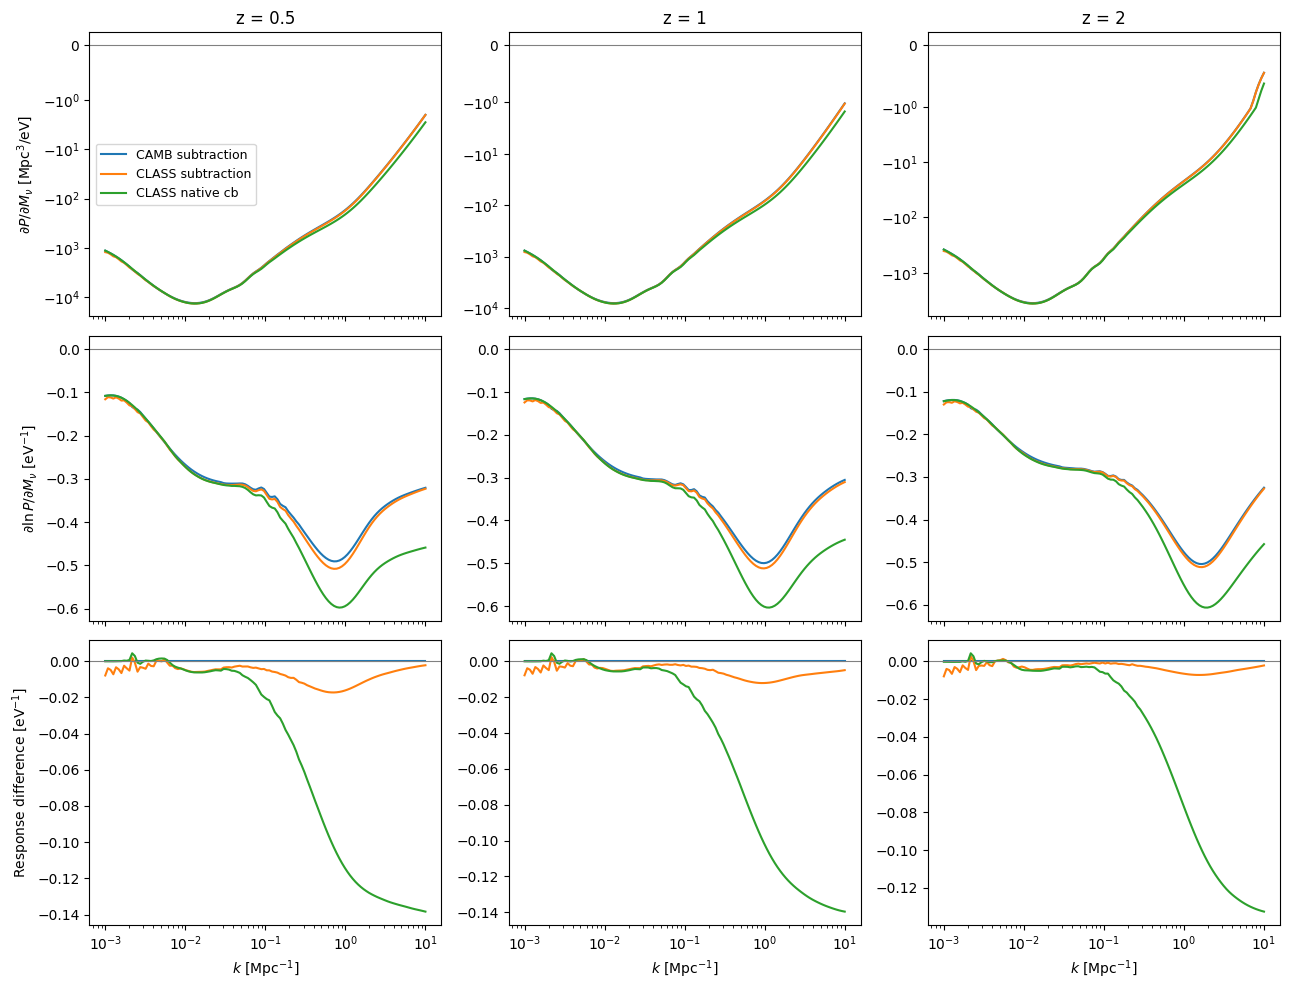

In [8]:
dP = {name: (p[2] - p[0])/(2*dm) for name, p in spectra.items()}
dlogP = {name: (np.log(p[2]) - np.log(p[0]))/(2*dm)
         for name, p in spectra.items()}
fig, axes = plt.subplots(3, len(z), figsize=(13, 10), sharex=True)
for j, zz in enumerate(z):
    for name in spectra:
        axes[0, j].semilogx(k, dP[name][j], label=name)
        axes[1, j].semilogx(k, dlogP[name][j])
        axes[2, j].semilogx(k, dlogP[name][j] - dlogP["CAMB subtraction"][j])
    axes[0, j].set_yscale("symlog", linthresh=1)
    axes[0, j].set_title(f"z = {zz:g}")
    axes[2, j].set_xlabel(r"$k$ [Mpc$^{-1}$]")
    for ax in axes[:, j]:
        ax.axhline(0, color="gray", lw=0.8)
axes[0, 0].set_ylabel(r"$\partial P/\partial M_\nu$ [Mpc$^3$/eV]")
axes[1, 0].set_ylabel(r"$\partial\ln P/\partial M_\nu$ [eV$^{-1}$]")
axes[2, 0].set_ylabel(r"Response difference [eV$^{-1}$]")
axes[0, 0].legend(fontsize=9)
fig.tight_layout()
plt.show()